# Week 11 In-Class Demo 2
## Improving a Health Classification Pipeline with Cross-Validation and Hyperparameter Tuning

### Business question
We continue with the **same synthetic health dataset used in Demo 1**. The organization still wants to identify patients who may be readmitted within 30 days so that limited follow-up resources can be planned more effectively.

Demo 1 built a clean, reproducible pipeline. Demo 2 asks a different question:

> **How can we compare model settings more fairly and choose a workflow that better supports the business objective?**

The data are synthetic and intended only for teaching. The output is not a clinical recommendation.

## How this builds on Demo 1 and Week 10
You already know the basic idea of classification and have now seen a complete preprocessing pipeline.

Demo 2 adds three ideas:

1. **Cross-validation:** evaluate a workflow on several different training/validation partitions rather than relying on one split.
2. **Hyperparameters:** settings chosen by the analyst before model fitting.
3. **Grid search:** systematically compare a small set of reasonable hyperparameter combinations.

For BBA students, the goal is not to memorize scikit-learn syntax. The goal is to understand **why a model was selected and whether the selection process supports a business decision**.

## Lecture 20 resources
- [Lecture 20 recording](https://nait.video.yuja.com/V/Video?v=1347392&node=7565690&a=992776698)
- [Lecture 20 reference notebook](https://nbviewer.org/github/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/lectures/Lecture20_pipeline_part_2.ipynb)
- [Student workbook: Lectures 19–20](https://github.com/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/workbooks/Lecture19_20_workbook.ipynb)
- [Student workbook solution](https://colab.research.google.com/drive/18WBBlkbv0hG263aULFziahDP4pIQDkuG?usp=sharing)
- [O’Reilly book: *Machine Learning with Python for Everyone*](https://learning.oreilly.com/library/view/machine-learning-with/9780134845708/)
  - **Chapter 11: Tuning Hyperparameters and Pipelines**
- [Machine Learning Assignment 2](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=dropbox&rcode=EE964922-8905-4C5B-ACC8-340F77B2A0B1-551201)
- [Term Project](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=dropbox&rcode=EE964922-8905-4C5B-ACC8-340F77B2A0B1-551222)

## What you will do
By the end of Demo 2, you should be able to:

- distinguish a model **parameter** from a **hyperparameter**;
- explain five-fold cross-validation in plain language;
- explain why preprocessing must remain inside the pipeline during cross-validation;
- read nested parameter names such as `classifier__class_weight`;
- use a small `GridSearchCV` search to compare candidate workflows;
- compare model selection based on accuracy versus recall;
- protect the final test set from repeated model-selection decisions;
- communicate the trade-off between overall accuracy and finding more readmissions.

## The Demo 2 story in plain business language
Imagine that a manager asks, “Can we improve the readmission workflow from Demo 1?”

A responsible analyst should not simply try settings until the test score looks good. Instead:

1. keep the final test set protected;
2. use the training data to compare candidate workflows;
3. repeat the comparison across several folds so one unusual split has less influence;
4. decide which metric defines “better” for the business problem;
5. evaluate the selected workflow on the protected test set only after selection.

This is the logic behind cross-validation and grid search. The Python tools automate the repetition, but the analyst still defines the candidates and the business objective.

## One dataset throughout both demonstrations
Demo 2 reads the same file: `healthcare_readmission.csv`.

To make the comparison fair, we repeat the **same documented cleaning rules and the same train-test split** used in Demo 1. The new work begins after the preprocessing pipeline has been reconstructed.

This repetition is intentional. A reproducible workflow should produce the same clean analytical dataset when the same raw file and rules are used.

## Before the setup code: the new tools in Demo 2
Most imports are familiar from Demo 1. Four items deserve special attention:

| Tool | Plain-language role |
|---|---|
| `StratifiedKFold` | Creates repeatable folds while preserving approximately the same class proportions |
| `cross_validate` | Repeats fitting/evaluation across folds and returns several metrics |
| `GridSearchCV` | Tests a defined list of hyperparameter combinations using cross-validation |
| `precision_score`, `recall_score`, `f1_score` | Quantify different kinds of classification performance |

Do not memorize the function signatures. First understand what decision each tool supports.

In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
print("Setup complete.")

Setup complete.


## 1. Recreate the Demo 1 analytical dataset
The next cell deliberately repeats the cleaning rules from Demo 1:

- standardize missing tokens;
- remove exact duplicates;
- convert numerical columns;
- flag values outside the teaching ranges as missing;
- standardize categorical aliases;
- recreate the same two engineered features.

We are **not introducing new cleaning decisions**. Changing the data at the same time as changing model settings would make it harder to identify why performance changed.

### Why repeat the data preparation instead of importing Demo 1 output?
For teaching, Demo 2 is self-contained. A student can run it using the same CSV even if Demo 1 is closed.

More importantly, reproducing the same analytical dataset demonstrates a professional principle: **the raw data plus documented rules should recreate the modeling dataset**.

The cleaning cell is long because it repeats known rules. We do not spend class time re-teaching every line. The new learning begins with validation and hyperparameter selection.

In [97]:
DATA_PATH = "healthcare_readmission.csv"
df_raw = pd.read_csv(DATA_PATH, low_memory=False)
df = df_raw.copy()

df = df.replace(["", "NA", "N/A", "unknown", "Unknown"], np.nan)
df = df.drop_duplicates().copy()

numeric_columns = [
    "age", "bmi", "systolic_bp", "cholesterol_mmol_l", "hba1c_pct",
    "chronic_conditions", "prior_admissions", "avg_visit_cost",
    "appointment_wait_days", "missed_appointments"
]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

valid_ranges = {
    "age": (18, 100), "bmi": (12, 70), "systolic_bp": (70, 250),
    "cholesterol_mmol_l": (1, 15), "hba1c_pct": (3, 20),
    "chronic_conditions": (0, 15), "prior_admissions": (0, 20),
    "avg_visit_cost": (0, 20000), "appointment_wait_days": (0, 365),
    "missed_appointments": (0, 30)
}
for col, (low, high) in valid_ranges.items():
    invalid = df[col].notna() & ~df[col].between(low, high)
    df.loc[invalid, col] = np.nan

categorical_columns = ["gender", "region", "smoker_status", "activity_level", "insurance_type"]
for col in categorical_columns:
    df[col] = df[col].astype("string").str.strip().str.lower()

category_maps = {
    "gender": {"f":"Female", "female":"Female", "m":"Male", "male":"Male", "nb":"Non-binary", "nonbinary":"Non-binary", "non-binary":"Non-binary"},
    "region": {"edmonton":"Edmonton", "edm":"Edmonton", "calgary":"Calgary", "yyc":"Calgary", "central alberta":"Central Alberta", "northern alberta":"Northern Alberta", "north":"Northern Alberta", "southern alberta":"Southern Alberta", "south":"Southern Alberta"},
    "smoker_status": {"never":"Never", "n":"Never", "former":"Former", "current":"Current", "y":"Current"},
    "activity_level": {"low":"Low", "moderate":"Moderate", "high":"High"},
    "insurance_type": {"employer":"Employer", "govt":"Government", "government":"Government", "private":"Private", "un-insured":"Uninsured", "uninsured":"Uninsured"}
}
for col, mapping in category_maps.items():
    df[col] = df[col].map(mapping).astype(object)
    df[col] = df[col].where(pd.notna(df[col]), np.nan)

df["high_service_use"] = np.where(
    (df["prior_admissions"] >= 2) | (df["missed_appointments"] >= 3), "Yes", "No"
)
df["risk_measure_count"] = (
    (df["bmi"] >= 30).fillna(False).astype(int)
    + (df["systolic_bp"] >= 140).fillna(False).astype(int)
    + (df["hba1c_pct"] >= 6.5).fillna(False).astype(int)
)

print("Raw rows:", len(df_raw))
print("Analytical rows:", len(df))
print("Readmission rate:", round(df["readmitted_30d"].mean(), 3))

Raw rows: 120500
Analytical rows: 120000
Readmission rate: 0.144


## Check-in 1: Why repeat the same cleaning rules?

<details>
<summary><strong>Reveal explanation</strong></summary>

If we changed the data-cleaning rules and the model settings at the same time, a performance difference could come from either change.

Keeping the data preparation fixed creates a fairer comparison. This is a general business-analysis principle: **when comparing alternatives, hold unrelated conditions constant whenever possible.**

</details>

## 2. Recreate the same protected train-test split
The final test set continues to play the same role as in Demo 1. We do not use it to choose hyperparameters.

The training set is where model selection happens. The test set is reserved for a final check after the selection process is complete.

### Why the protected test set still matters
Demo 2 introduces many comparisons. That makes it even easier to accidentally use the test set as a scoreboard.

We therefore use the training set for cross-validation and grid search. `X_test` and `y_test` remain untouched until the end.

A helpful analogy is:

- **training/CV data = practice and selection**;
- **test data = final audit**.

If we repeatedly change settings after checking the test result, the “final audit” is no longer independent.

In [101]:
X = df.drop(columns=["patient_id", "readmitted_30d"])
y = df["readmitted_30d"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training readmission rate:", round(y_train.mean(), 3))
print("Test readmission rate:", round(y_test.mean(), 3))

Training rows: 96000
Test rows: 24000
Training readmission rate: 0.144
Test readmission rate: 0.144


## 3. Rebuild the same preprocessing pipeline
The preprocessing is unchanged from Demo 1. Numerical variables receive median imputation and scaling. Categorical variables receive most-frequent imputation and one-hot encoding.

The important point for Demo 2 is that the preprocessing stays **inside** the pipeline. During cross-validation, scikit-learn will refit these preprocessing steps separately for each training fold.

### Why rebuild the entire pipeline before cross-validation?
Cross-validation should evaluate what we would actually deploy, not only the final classifier.

Our deployable workflow includes:

`raw analytical record → imputation → scaling/encoding → logistic regression`

Because preprocessing is inside `Pipeline`, each fold learns its own medians, scaling statistics, category frequencies, one-hot categories, and model coefficients using only that fold's training portion. This is the safest way to prevent validation leakage.

In [104]:
numeric_features = [
    "age", "bmi", "systolic_bp", "cholesterol_mmol_l", "hba1c_pct",
    "chronic_conditions", "prior_admissions", "avg_visit_cost",
    "appointment_wait_days", "missed_appointments", "risk_measure_count"
]
categorical_features = [
    "gender", "region", "smoker_status", "activity_level", "insurance_type", "high_service_use"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

baseline = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

baseline

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'bmi', 'systolic_bp',
                                                   'cholesterol_mmol_l',
                                                   'hba1c_pct',
                                                   'chronic_conditions',
                                                   'prior_admissions',
                                                   'avg_visit_cost',
                                                   'appointment_wait_days',
                                                   'missed_appointments',
                                                   'risk_measure_count']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'region',
                                                   'smoker_status',
                                                   'activity_level',
                                                   'insurance_type',
                                                   'high_service_use'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

## 4. Parameters versus hyperparameters
This vocabulary is easier with an example.

### Parameter
A parameter is learned from the data during `.fit()`. Logistic-regression coefficients are parameters. We do not manually type their final values.

### Hyperparameter
A hyperparameter is a setting chosen before fitting. Two useful examples are:

- `C`: controls the strength of regularization in logistic regression. Smaller `C` means stronger regularization.
- `class_weight`: controls how much the fitting process emphasizes each class. `"balanced"` gives more relative weight to the less-common readmission class.

Hyperparameters are not automatically better at larger values. We compare reasonable candidates.

## Check-in 2: Parameter or hyperparameter?
Classify each item:

1. logistic-regression coefficient;
2. `C=1.0`;
3. `class_weight="balanced"`;
4. median learned by the imputer.

<details>
<summary><strong>Reveal solution</strong></summary>

1. Logistic-regression coefficient: **parameter**, learned during fitting.
2. `C=1.0`: **hyperparameter**, chosen before fitting.
3. `class_weight="balanced"`: **hyperparameter**, chosen before fitting.
4. Training median: a **learned preprocessing value**, not a model hyperparameter. It is estimated from the training data by the imputer.

</details>

## 🎥 Before We Code: Cross-Validation and Grid Search
Before looking at the Python implementation, watch this short explanation of cross-validation and grid search with a scikit-learn pipeline.

### Embedded video
Run the video cell directly below. If your notebook environment blocks embedded YouTube playback, use the fallback link:

[Open the Data School video in a new tab](https://www.youtube.com/watch?v=f_xB7kbZR_g)

The video is a good match for this demonstration because it emphasizes one especially important idea: **the preprocessing pipeline should be cross-validated together with the model**.

### While watching, focus on three questions
1. Why might one train/validation split give an incomplete picture of model performance?
2. What changes from one cross-validation fold to another?
3. How does grid search use repeated validation to compare model settings?

### BBA mental model
Think of **cross-validation** as giving each candidate workflow several practice evaluations instead of only one.

Think of **grid search** as a structured comparison table:

> “For each reasonable set of model settings, repeat the same evaluation process and summarize the results.”

The computer performs the repetitive fitting. The analyst still decides which settings are reasonable, which metric defines “better,” and whether the resulting trade-off makes business sense.

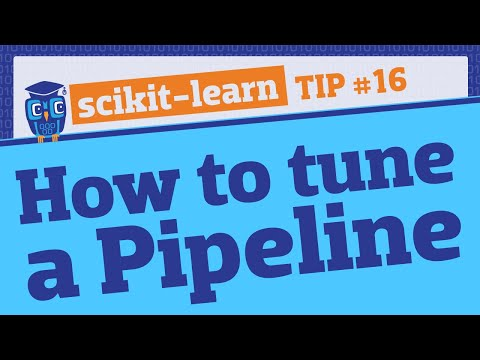

In [153]:
# Display the cross-validation / GridSearchCV video inside Jupyter or Colab.
from IPython.display import YouTubeVideo, display

display(YouTubeVideo("f_xB7kbZR_g", width=800, height=450))

## Video check-in: Connect the idea to our health dataset
Before continuing, answer these questions using our readmission example.

1. During five-fold cross-validation, do we repeatedly divide the **protected test set**?
2. Should the imputer and scaler be fitted once before the folds are created?
3. If grid search tests 6 candidate workflows with 5 folds, how many validation fits are required?

<details>
<summary><strong>Reveal solution</strong></summary>

1. **No.** Cross-validation operates inside the training data. The protected test set remains outside model selection.
2. **No.** The imputer, scaler, encoder, and model should be fitted inside each fold's training portion. Keeping them together in `Pipeline` helps prevent validation leakage.
3. `6 candidates × 5 folds = 30 validation fits`. If `refit=True`, scikit-learn then fits the selected workflow one additional time using all training rows.

The key idea is that grid search is not a separate modeling trick. It is a systematic way to repeat the same validation process for several candidate settings.

</details>

## 5. Why use cross-validation?
A single train-validation split can be lucky or unlucky. Cross-validation rotates which training records are temporarily held out for validation.

### Five-fold cross-validation
With five folds:

1. divide the training set into five groups;
2. fit the complete pipeline using four groups;
3. evaluate it on the remaining group;
4. repeat until every group has served as validation once;
5. summarize the five scores.

The **protected test set is not one of these folds**. It remains outside the selection process.

### Why `StratifiedKFold`?
The readmission class is less common than the non-readmission class. `StratifiedKFold` tries to keep approximately the same class proportion in each fold.

We also use `shuffle=True` with `random_state=42` so the fold assignment is reproducible in class.

### Reading the cross-validation code step by step
`StratifiedKFold(...)` defines **how** the folds are created. `cross_validate(...)` then performs the repeated experiment.

The `scoring` dictionary asks for four views of performance at the same time:

- `accuracy`: overall percentage correct;
- `recall`: share of actual readmissions detected;
- `precision`: share of readmission alerts that are correct;
- `f1`: one combined summary of precision and recall.

`n_jobs=-1` asks scikit-learn to use available processor cores. It changes computation speed, not the statistical logic.

The result contains one score per fold. We then calculate the mean and standard deviation to summarize typical performance and fold-to-fold variation.

In [113]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring={"accuracy":"accuracy", "recall":"recall", "precision":"precision", "f1":"f1"},
    n_jobs=-1
)

cv_summary = pd.DataFrame({
    "accuracy": cv_results["test_accuracy"],
    "recall": cv_results["test_recall"],
    "precision": cv_results["test_precision"],
    "f1": cv_results["test_f1"]
})
display(cv_summary.round(3))
display(cv_summary.agg(["mean", "std"]).round(3))

,accuracy,recall,precision,f1
0,0.864,0.153,0.618,0.245
1,0.863,0.152,0.601,0.242
2,0.866,0.147,0.654,0.241
3,0.863,0.144,0.606,0.232
4,0.863,0.152,0.603,0.243


,accuracy,recall,precision,f1
mean,0.864,0.150,0.617,0.241
std,0.001,0.004,0.022,0.005


## Check-in 3: Why is preprocessing inside each fold?

<details>
<summary><strong>Reveal explanation</strong></summary>

During each fold, the imputer, scaler, encoder, and model must learn only from that fold's training portion.

If we imputed or scaled the complete training set before cross-validation, the temporary validation fold would influence those learned values. Keeping preprocessing inside `Pipeline` prevents that leakage automatically.

</details>

## Check-in 4: Read a five-fold result
Suppose recall across five folds is:

`0.14, 0.16, 0.15, 0.14, 0.17`

What do the mean and the small spread tell a manager?

<details>
<summary><strong>Reveal explanation</strong></summary>

The average recall is around 0.15, so the workflow identifies only about 15% of actual readmissions. The scores are also close together, suggesting this low recall is fairly consistent across these folds.

The key lesson is that **stability is not the same as good business performance**. A consistently low recall can still be unacceptable for a readmission-support objective.

</details>

## 6. What does the baseline CV result tell us?
Look at both the **mean** and the **variation across folds**.

- Mean accuracy tells us typical overall classification performance across the five validation folds.
- Mean recall tells us what share of actual readmissions the workflow typically detects.
- Standard deviation tells us how much the score changes when a different fold is used for validation.

A stable but low recall is still a business concern. Consistency does not automatically imply usefulness.

## 7. Read nested pipeline parameter names
Grid search needs to know exactly which setting belongs to which step.

Scikit-learn separates nested names with two underscores:

- `classifier__C` means the `C` setting inside the step named `classifier`.
- `classifier__class_weight` means the class-weight setting inside that same model.
- `preprocess__num__imputer__strategy` would reach even deeper into the numerical imputer.

The naming follows the structure of the pipeline rather than requiring special syntax for each model.

### Why inspect parameter names before grid search?
Pipeline objects are nested. Instead of guessing a parameter name and receiving an error, `get_params()` lets us inspect the names scikit-learn recognizes.

Read the name from left to right. For `classifier__class_weight`:

1. go to the pipeline step named `classifier`;
2. change its `class_weight` setting.

For a more deeply nested name such as `preprocess__num__imputer__strategy`, each double underscore moves one level deeper.

In [119]:
interesting_parameters = [
    name for name in baseline.get_params().keys()
    if name in ["classifier__C", "classifier__class_weight", "preprocess__num__imputer__strategy"]
]
interesting_parameters

['preprocess__num__imputer__strategy',
 'classifier__C',
 'classifier__class_weight']

## Check-in 5: Decode this name
What does `preprocess__num__imputer__strategy` mean?

<details>
<summary><strong>Reveal solution</strong></summary>

- `preprocess`: enter the preprocessing `ColumnTransformer`;
- `num`: enter its numerical branch;
- `imputer`: enter the numerical imputer step;
- `strategy`: the setting that could be changed, for example `"median"` or `"mean"`.

The name follows the structure of the pipeline. It is not four unrelated commands.

</details>

## 8. Design a small, understandable grid
For class demonstration, we intentionally keep the grid small:

- `C`: `0.1`, `1.0`, `10.0`;
- class weight: normal weighting or `"balanced"`.

That gives `3 × 2 = 6` candidate workflows. With five folds, grid search performs **30 validation fits**, then refits the winning workflow on all training rows.

A larger grid is not automatically more professional. Every candidate should have a reason, and computation grows quickly as more values are added.

### Before running grid search: calculate the workload
The grid has three `C` values and two class-weight choices:

`3 × 2 = 6 candidate workflows`

Each candidate is evaluated across five folds:

`6 × 5 = 30 cross-validation fits`

With `refit=True`, scikit-learn then fits the winning candidate once more using all training rows.

This arithmetic matters in real projects. Five hyperparameters with ten values each could create `10^5 = 100,000` combinations before folds are even considered.

## Check-in 6: Change the grid size
If we added 3 imputation strategies to the current 6 model combinations and still used 5 folds, how many validation fits would be required?

<details>
<summary><strong>Reveal solution</strong></summary>

The new grid would contain:

`3 C values × 2 class-weight choices × 3 imputation choices = 18 candidates`

With five folds:

`18 × 5 = 90 validation fits`

This is why thoughtful grids are preferable to simply adding many values.

</details>

In [124]:
param_grid = {
    "classifier__C": [0.1, 1.0, 10.0],
    "classifier__class_weight": [None, "balanced"]
}

accuracy_search = GridSearchCV(
    estimator=baseline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)
accuracy_search.fit(X_train, y_train)

print("Best mean CV accuracy:", round(accuracy_search.best_score_, 3))
print("Best settings:", accuracy_search.best_params_)

Best mean CV accuracy: 0.864
Best settings: {'classifier__C': 0.1, 'classifier__class_weight': None}


## 9. Do not look only at the winning row
`GridSearchCV` stores every candidate result. Important columns include:

- `mean_test_score`: average validation performance;
- `std_test_score`: variation across folds;
- `mean_train_score`: average performance on fitting folds;
- `rank_test_score`: rank under the selected scoring metric.

When two workflows are nearly tied, a simpler or more stable choice may be preferable to chasing a tiny numerical difference.

### How to read the grid-search results table
Each row represents one candidate workflow.

- `rank_test_score = 1` marks the best mean validation score under the chosen metric.
- `mean_test_score` is the average validation score across folds.
- `std_test_score` shows how much the validation score changes across folds.
- `mean_train_score` summarizes performance on the fitting portions of the folds.

If training performance is much stronger than validation performance, overfitting may be a concern. If several candidates have almost identical validation scores, the score alone may not justify choosing the more complicated option.

In [127]:
accuracy_results = pd.DataFrame(accuracy_search.cv_results_)
cols = [
    "rank_test_score", "mean_test_score", "std_test_score", "mean_train_score",
    "param_classifier__C", "param_classifier__class_weight"
]
display(accuracy_results[cols].sort_values("rank_test_score").round(3))

,rank_test_score,mean_test_score,std_test_score,mean_train_score,param_classifier__C,param_classifier__class_weight
0,1,0.864,0.001,0.864,0.1,None
2,2,0.864,0.001,0.864,1.0,None
4,2,0.864,0.001,0.864,10.0,None
1,4,0.712,0.003,0.713,0.1,balanced
5,5,0.712,0.004,0.713,10.0,balanced
3,6,0.712,0.004,0.713,1.0,balanced


## Check-in 7: What problem does accuracy create here?
Our target is imbalanced. Most records are not readmitted.

<details>
<summary><strong>Reveal explanation</strong></summary>

An accuracy-focused search can prefer a workflow that performs very well on the common non-readmission class while identifying relatively few actual readmissions.

That can be mathematically accurate but operationally weak if the organization's purpose is to find patients who may need follow-up support.

The metric used for model selection should reflect the decision objective, not simply produce the largest-looking number.

</details>

## 10. Repeat the same grid using readmission recall
Now we change only the **selection metric**. The candidate models and data remain the same.

This is an important business lesson: the definition of “best model” depends partly on what the organization values.

If missing a potential readmission is costly and follow-up contact is relatively inexpensive, recall can be more important than overall accuracy.

### Why rerun the same grid with a different metric?
Nothing in the candidate list changes. The only change is the definition of “best.”

- Accuracy rewards being correct across **all** records.
- Recall rewards identifying a larger share of the **actual readmissions**.

Because non-readmissions are much more common, these objectives can prefer different workflows. This is the key managerial lesson in Demo 2: **a model-selection metric encodes what the analysis is prioritizing.**

In [131]:
recall_search = GridSearchCV(
    estimator=baseline,
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    refit=True
)
recall_search.fit(X_train, y_train)

print("Best mean CV recall:", round(recall_search.best_score_, 3))
print("Best settings:", recall_search.best_params_)

Best mean CV recall: 0.702
Best settings: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}


## 11. Compare what each objective selected
The accuracy search and recall search may select different class weighting because they reward different behaviour.

This does **not** mean one metric is universally correct. An organization should consider:

- cost of an unnecessary follow-up;
- cost or consequence of a missed readmission opportunity;
- staff capacity;
- patient experience;
- how predictions will actually be used.

Model selection is therefore both a technical and a managerial decision.

### Compare the selected settings before touching the final test set
At this stage, both selections are based entirely on cross-validation within the training data.

We compare:

- which `C` value was selected;
- whether normal or balanced class weighting was selected;
- the best CV score under each search's own objective.

Do not compare the two `Best CV score` values as though they were the same metric. One is accuracy and the other is recall.

In [134]:
comparison = pd.DataFrame({
    "Selection objective": ["Accuracy", "Recall"],
    "Best CV score": [accuracy_search.best_score_, recall_search.best_score_],
    "C": [accuracy_search.best_params_["classifier__C"], recall_search.best_params_["classifier__C"]],
    "Class weight": [str(accuracy_search.best_params_["classifier__class_weight"]), str(recall_search.best_params_["classifier__class_weight"])]
})
display(comparison.round(3))

,Selection objective,Best CV score,C,Class weight
0,Accuracy,0.864,0.1,None
1,Recall,0.702,0.1,balanced


## 12. Final test-set comparison
Only now do we use the protected test set.

We compare the two workflows chosen by different business objectives. We should resist changing the grid repeatedly after seeing these test results, because that would gradually turn the test set into another model-selection tool.

### One final evaluation, several metrics
The two selected workflows are now evaluated against exactly the same protected test records.

The helper function avoids repeating metric code. For each selected model it reports accuracy, precision, recall, and F1 so the trade-off is visible in one table.

This is deliberately the first point at which the test set enters model comparison.

In [137]:
def test_metrics(name, fitted_model):
    p = fitted_model.predict(X_test)
    return {
        "model": name,
        "accuracy": accuracy_score(y_test, p),
        "precision": precision_score(y_test, p, zero_division=0),
        "recall": recall_score(y_test, p, zero_division=0),
        "f1": f1_score(y_test, p, zero_division=0)
    }

final_comparison = pd.DataFrame([
    test_metrics("Selected for accuracy", accuracy_search.best_estimator_),
    test_metrics("Selected for recall", recall_search.best_estimator_)
])
display(final_comparison.round(3))

,model,accuracy,precision,recall,f1
0,Selected for accuracy,0.865,0.647,0.150,0.244
1,Selected for recall,0.711,0.293,0.705,0.414


### Interpreting the actual result
In this synthetic dataset, the two objectives lead to a large operational trade-off:

- the accuracy-selected workflow has test accuracy around **0.865** but readmission recall around **0.150**;
- the recall-selected workflow has lower test accuracy around **0.711** but readmission recall around **0.705**.

In plain language, the recall-selected workflow finds far more actual readmissions, but it also creates many more false-positive alerts. That could require substantially more follow-up capacity.

The notebook does not declare a universal winner. The appropriate choice depends on intervention cost, available staff, patient impact, and the organization's tolerance for missed readmissions versus unnecessary outreach.

## 13. Visualize the business trade-off
A small table is useful, but a chart makes the trade-off easier to discuss with a non-technical audience.

The chart below compares accuracy and readmission recall for the two selected workflows. A workflow can improve recall while giving up some overall accuracy.

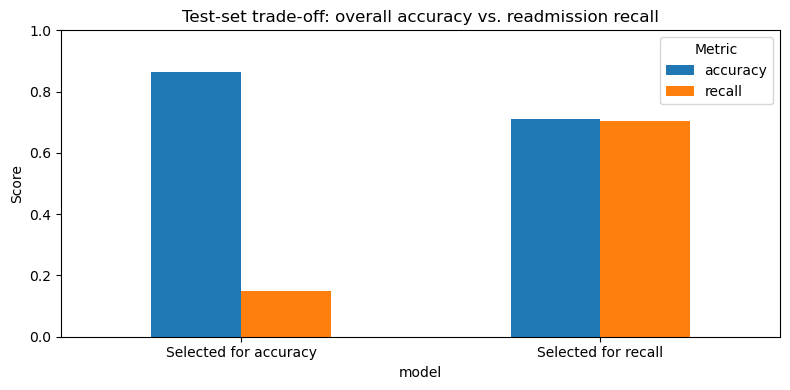

In [140]:
plot_data = final_comparison.set_index("model")[["accuracy", "recall"]]
ax = plot_data.plot(kind="bar", figsize=(8, 4), ylim=(0, 1))
ax.set_ylabel("Score")
ax.set_title("Test-set trade-off: overall accuracy vs. readmission recall")
ax.legend(title="Metric")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Check-in 8: Which model would you recommend?
Do not answer with only “the one with the higher score.” State the decision context.

<details>
<summary><strong>Reveal a strong business answer</strong></summary>

If the organization has enough follow-up capacity and the cost of contacting a patient unnecessarily is modest relative to missing a potentially useful intervention, the recall-selected workflow may be more appropriate because it identifies a larger share of actual readmissions.

If follow-up capacity is extremely limited or unnecessary outreach is costly, precision and workload may deserve more emphasis.

A responsible recommendation should therefore report the trade-off, expected volume of alerts, operational capacity, and uncertainty rather than claiming one model is always best.

</details>

## 14. Assignment 2 transfer
Assignment 2 asks your group to compare classification models and evaluate performance. The Demo 2 principles transfer directly:

- keep preprocessing inside the pipeline;
- compare candidate models/settings using training-data validation;
- select metrics that fit the prediction problem;
- keep final test data out of model-selection decisions;
- explain why the selected workflow is appropriate rather than reporting only its score.

Your group's exact models, search space, and metric priorities should come from your own dataset and results.

## 15. Term Project transfer
The Term Project includes both Salary regression and Salary Grade classification.

For either task, the model-selection logic is similar:

1. define the prediction problem clearly;
2. build a leakage-safe preprocessing/model pipeline;
3. choose candidate settings deliberately;
4. compare them using a consistent validation process;
5. select evaluation measures that match the task;
6. reserve test data for a final evaluation.

For the Salary Grade classifier, remember that `Salary` directly defines the target and therefore must not be used as a predictor.

## Final student review checklist

### Cross-validation
- [ ] I can explain why one validation split may be unstable.
- [ ] I can describe five-fold cross-validation without code.
- [ ] I can explain why the protected test set is separate from the CV folds.
- [ ] I can explain why preprocessing stays inside the pipeline during CV.

### Hyperparameters and grid search
- [ ] I can distinguish parameters, learned preprocessing values, and hyperparameters.
- [ ] I can read `classifier__C` and `classifier__class_weight`.
- [ ] I can calculate candidate combinations × folds.
- [ ] I understand that a larger grid is not automatically better.
- [ ] I can interpret mean validation score and fold-to-fold variability.

### Business model selection
- [ ] I can explain why accuracy may be misleading with an imbalanced target.
- [ ] I can explain why selecting for recall can change the chosen workflow.
- [ ] I can compare accuracy, precision, recall, and F1 in business language.
- [ ] I can protect the test set from repeated selection decisions.
- [ ] I can recommend a workflow using the decision context, not only the largest score.

<details>
<summary><strong>Reveal the complete Demo 2 workflow</strong></summary>

1. Recreate the same analytical dataset and protected train-test split.
2. Rebuild the complete preprocessing/model pipeline.
3. Define a reproducible stratified cross-validation strategy.
4. Establish baseline CV performance.
5. Identify a small set of meaningful hyperparameters.
6. Calculate how many candidate fits the grid will require.
7. Run grid search using a stated selection metric.
8. inspect all candidate results, not only the winner.
9. compare what happens when the business objective changes.
10. Evaluate the selected workflows once on protected test data.
11. interpret the trade-off in terms of operational costs and capacity.

</details>

## Exit ticket
Explain in four or five sentences:

1. why cross-validation is more informative than one validation split;
2. what a hyperparameter is;
3. why preprocessing remains inside the pipeline;
4. why accuracy and recall can select different workflows;
5. what information a manager would need before choosing between those workflows.